# 8장. 작은 데이터 분석 프로젝트 완성하기

이 노트북은 데이터 점검, 전처리, 병합 검증, 완료 주문 기준 집계, 시각화, 보고서 작성을 하나의 재현 가능한 프로젝트로 연결합니다.


## 학습 목표

- 원본 데이터를 보존하며 전처리합니다.
- 주요 키 중복과 외래키 미매칭을 확인합니다.
- `validate`와 `indicator`를 사용한 병합 검증 원리를 확인합니다.
- 취소·환불 주문을 제외하고 완료 주문 기준 매출을 계산합니다.
- 고객 이름을 노출하지 않는 익명화 결과를 만듭니다.
- 결과 CSV, 그래프, Markdown 보고서를 재현 가능하게 저장합니다.


## 1. 프로젝트 루트와 출력 폴더 설정

VS Code에서 현재 작업 폴더가 프로젝트 루트 또는 `notebooks`일 수 있으므로 상위 폴더를 탐색합니다.


In [29]:
from pathlib import Path
import sys

import pandas as pd


def find_project_root(start_path):
    start_path = Path(start_path).resolve()
    for candidate in [start_path, *start_path.parents]:
        if (candidate / 'requirements.txt').exists() and (candidate / 'scripts').exists():
            return candidate
    raise FileNotFoundError('프로젝트 루트 폴더를 찾을 수 없습니다.')


PROJECT_ROOT = find_project_root(Path.cwd())
RAW_DIR = PROJECT_ROOT / 'data' / 'raw'
PROCESSED_DIR = PROJECT_ROOT / 'data' / 'processed'
REPORT_DIR = PROJECT_ROOT / 'reports'
FIGURE_DIR = REPORT_DIR / 'figures'

for path in [PROCESSED_DIR, REPORT_DIR, FIGURE_DIR]:
    path.mkdir(parents=True, exist_ok=True)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print('Python 실행 파일:', sys.executable)
print('프로젝트 루트:', PROJECT_ROOT)
print('원본 데이터 폴더:', RAW_DIR)
print('보고서 폴더:', REPORT_DIR)


Python 실행 파일: c:\Users\bbine\00_Default\02_Dev\llm-data-analysis-course\.venv\Scripts\python.exe
프로젝트 루트: C:\Users\bbine\00_Default\02_Dev\llm-data-analysis-course
원본 데이터 폴더: C:\Users\bbine\00_Default\02_Dev\llm-data-analysis-course\data\raw
보고서 폴더: C:\Users\bbine\00_Default\02_Dev\llm-data-analysis-course\reports


## 2. 프로젝트 함수 불러오기

중간 프로젝트의 공통 로직은 `src/` 모듈에 정리되어 있습니다. Notebook과 일괄 실행 스크립트가 같은 함수를 사용하므로 계산 기준이 어긋나는 문제를 줄일 수 있습니다.


In [30]:
from src.data_loader import load_sales_data
from src.preprocessing import (
    compare_shapes,
    preprocess_sales_data,
    save_processed_data,
    validate_relationships,
)
from src.midterm_project import (
    build_analysis_tables,
    build_interpretation_notes,
    build_key_duplicate_checks,
    build_midterm_report,
    create_project_figures,
    run_midterm_project,
    save_project_tables,
    summarize_datasets,
)


## 3. 원본 데이터 확인

파일이 없다면 프로젝트 루트에서 `python scripts/generate_sample_data.py`를 먼저 실행합니다.


In [31]:
raw_data = load_sales_data(RAW_DIR)

dataset_summary = summarize_datasets(raw_data)
display(dataset_summary)

for name, df in raw_data.items():
    print(f'\n===== {name} =====')
    print('shape:', df.shape)
    print('columns:', df.columns.tolist())
    print('missing values:', int(df.isna().sum().sum()))
    print('duplicated rows:', int(df.duplicated().sum()))


,dataset,rows,columns,missing_values,duplicated_rows
0,customers,150,6,0,0
1,products,100,4,0,0
2,orders,300,5,0,0
3,order_items,764,5,0,0



===== customers =====
shape: (150, 6)
columns: ['customer_id', 'name', 'gender', 'age', 'city', 'signup_date']
missing values: 0
duplicated rows: 0

===== products =====
shape: (100, 4)
columns: ['product_id', 'product_name', 'category', 'price']
missing values: 0
duplicated rows: 0

===== orders =====
shape: (300, 5)
columns: ['order_id', 'customer_id', 'order_date', 'payment_method', 'order_status']
missing values: 0
duplicated rows: 0

===== order_items =====
shape: (764, 5)
columns: ['order_item_id', 'order_id', 'product_id', 'quantity', 'unit_price']
missing values: 0
duplicated rows: 0


## 4. 원본을 보존하며 전처리

`preprocess_sales_data()`는 원본 DataFrame을 직접 수정하지 않고 전처리된 복사본을 반환합니다.


In [32]:
processed_data = preprocess_sales_data(raw_data)
processed_paths = save_processed_data(processed_data, PROCESSED_DIR)

preprocessing_comparison = compare_shapes(raw_data, processed_data)
display(preprocessing_comparison)

for path in processed_paths:
    print(path, 'OK' if path.exists() else 'MISSING')


,dataset,rows_raw,columns_raw,rows_processed,columns_processed
0,customers,150,6,150,6
1,order_items,764,5,764,6
2,orders,300,5,300,7
3,products,100,4,100,4


C:\Users\bbine\00_Default\02_Dev\llm-data-analysis-course\data\processed\customers_clean.csv OK
C:\Users\bbine\00_Default\02_Dev\llm-data-analysis-course\data\processed\products_clean.csv OK
C:\Users\bbine\00_Default\02_Dev\llm-data-analysis-course\data\processed\orders_clean.csv OK
C:\Users\bbine\00_Default\02_Dev\llm-data-analysis-course\data\processed\order_items_clean.csv OK


## 5. 키 중복과 관계 점검

전체 행 중복뿐 아니라 고객·상품·주문·주문 상세의 식별 키 중복을 확인합니다. 외래키가 기준 테이블에 존재하지 않는 행도 확인합니다.


In [33]:
key_duplicate_checks = build_key_duplicate_checks(processed_data)
relationship_checks = validate_relationships(processed_data)

display(key_duplicate_checks)
display(relationship_checks)


,dataset,key,duplicate_count
0,customers,customer_id,0
1,products,product_id,0
2,orders,order_id,0
3,order_items,order_item_id,0


,check,invalid_count
0,orders.customer_id exists in customers.custome...,0
1,order_items.order_id exists in orders.order_id,0
2,order_items.product_id exists in products.prod...,0


## 6. 안전한 병합과 완료 주문 기준 집계

`build_analysis_tables()`는 다음 기준을 적용합니다.

- 주문 상세와 주문: `many_to_one`
- 완료 주문만 매출 집계에 포함
- 주문 상세와 상품: `many_to_one`
- 고객 집계와 고객 속성: `one_to_one`
- 병합 전후 행 수와 미매칭 건수 기록


In [34]:
analysis_tables = build_analysis_tables(processed_data)

display(analysis_tables['merge_checks'])
display(analysis_tables['amount_scope_summary'])


,merge,before_rows,after_rows,row_count_preserved,unmatched_count
0,order_id → orders,764,764,True,0
1,product_id → products,474,474,True,0
2,customer_id → customers,100,100,True,0


,scope,amount,detail_rows
0,all_order_items,255610000.0,764
1,completed_order_items,148990000.0,474
2,excluded_cancelled_or_refunded,106620000.0,290


## 7. 주요 결과 확인

아래 매출표는 모두 완료 주문 기준입니다. 주문 상태별 요약표는 전체 주문을 대상으로 합니다.


In [35]:
category_sales = analysis_tables['category_sales']
monthly_sales = analysis_tables['monthly_sales']
customer_sales = analysis_tables['customer_sales']
order_status_summary = analysis_tables['order_status_summary']

display(category_sales)
display(monthly_sales)
display(
    customer_sales[
        ['customer_label', 'city', 'order_count', 'total_sales', 'avg_order_value']
    ].head(10)
)
display(order_status_summary)


,category,total_quantity,total_sales,sales_ratio
3,스포츠,295,31743000,21.31
5,전자기기,259,26400000,17.72
2,생활용품,272,23915000,16.05
1,뷰티,223,23383000,15.69
4,식품,133,16573000,11.12
0,도서,149,16389000,11.00
6,패션,111,10587000,7.11


,order_month,total_sales,order_count,avg_order_value
0,2025-09,2650000,5,530000.0
1,2025-10,16970000,19,893158.0
2,2025-11,11021000,13,847769.0
3,2025-12,21085000,23,916739.0
4,2026-01,14272000,16,892000.0
5,2026-02,4784000,7,683429.0
6,2026-03,18323000,25,732920.0
7,2026-04,11546000,16,721625.0
8,2026-05,16631000,19,875316.0
9,2026-06,12504000,17,735529.0


,customer_label,city,order_count,total_sales,avg_order_value
0,Customer 117,성남,5,4100000,820000.0
1,Customer 102,고양,4,3996000,999000.0
2,Customer 83,수원,4,3880000,970000.0
3,Customer 30,서울,5,3590000,718000.0
4,Customer 40,서울,4,3523000,880750.0
5,Customer 20,인천,2,3191000,1595500.0
6,Customer 3,성남,2,3178000,1589000.0
7,Customer 111,광주,3,3153000,1051000.0
8,Customer 66,서울,4,3093000,773250.0
9,Customer 147,부산,2,2990000,1495000.0


,order_status,order_count,order_ratio
0,completed,184,61.33
1,cancelled,64,21.33
2,refunded,52,17.33


## 8. 해석 메모와 결과 저장

관찰, 주의점, 다음 질문을 분리합니다. 고객 결과에는 실제 이름을 포함하지 않습니다.


In [36]:
interpretation_notes = build_interpretation_notes()
display(interpretation_notes)

saved_tables = save_project_tables(
    dataset_summary,
    preprocessing_comparison,
    key_duplicate_checks,
    relationship_checks,
    analysis_tables,
    interpretation_notes,
    REPORT_DIR,
)

for path in saved_tables:
    print(path.name, path.exists(), path.stat().st_size)


,analysis,observation,caution,next_question
0,카테고리별 완료 주문 매출,완료 주문 매출 비중이 높은 카테고리를 확인할 수 있습니다.,매출이 높은 이유가 판매 수량인지 단가인지 구분해야 합니다.,카테고리별 평균 판매 단가는 어떻게 다른가?
1,월별 완료 주문 매출,시간에 따른 완료 주문 매출의 증가와 감소를 확인할 수 있습니다.,프로모션이나 계절성이 원인이라고 단정할 수 없습니다.,주문 수와 평균 주문 금액 중 무엇이 변했는가?
2,고객별 완료 주문 구매 금액,완료 주문 구매 금액이 높은 고객군을 확인할 수 있습니다.,일회성 고액 구매와 반복 구매를 구분해야 합니다.,최근 구매일과 구매 빈도는 어떻게 다른가?
3,주문 상태별 주문 수,"완료, 취소, 환불 주문의 분포를 확인할 수 있습니다.",주문 상태의 정의와 처리 기준을 확인해야 합니다.,취소율과 환불률은 월별로 달라지는가?


ch08_dataset_summary.csv True 138
ch08_preprocessing_comparison.csv True 156
ch08_key_duplicate_checks.csv True 128
ch08_relationship_checks.csv True 184
ch08_merge_checks.csv True 187
ch08_amount_scope_summary.csv True 149
ch08_category_sales.csv True 254
ch08_monthly_sales.csv True 439
ch08_customer_sales.csv True 4333
ch08_order_status_summary.csv True 101
ch08_interpretation_notes.csv True 1036


## 9. 그래프 생성

그래프 제목에도 완료 주문 기준임을 표시합니다.


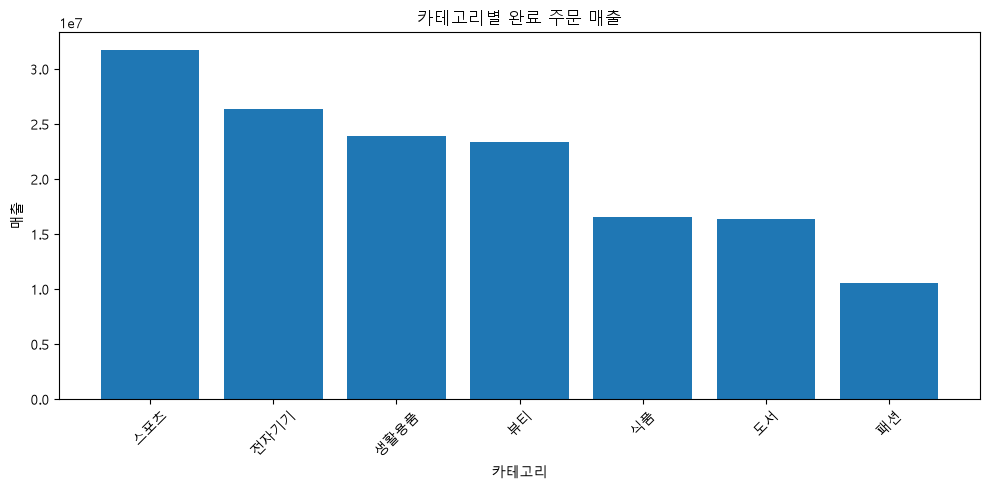

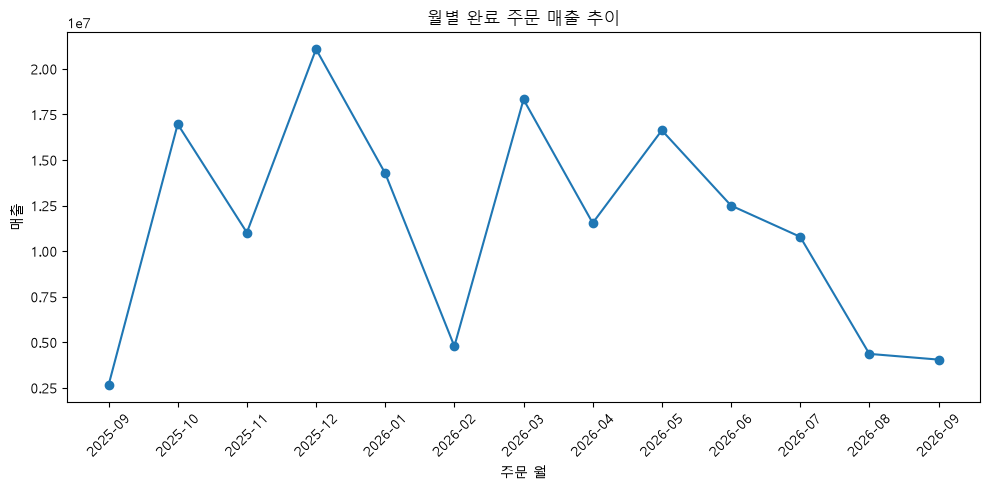

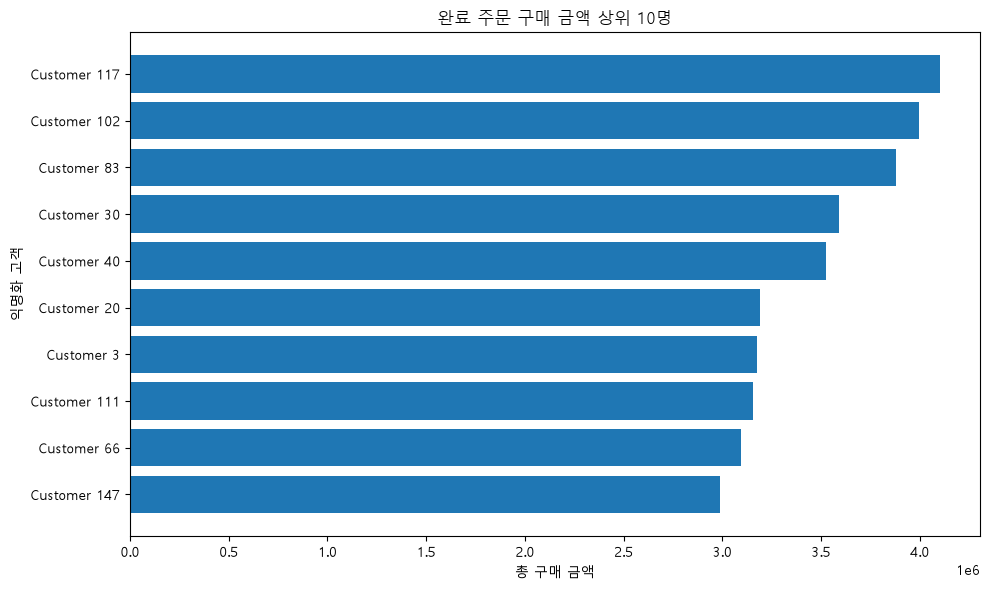

ch08_category_sales.png True 25830
ch08_monthly_sales.png True 79776
ch08_top_customers.png True 45556


In [37]:
saved_figures = create_project_figures(
    analysis_tables,
    FIGURE_DIR,
    show=True,
)

for path in saved_figures:
    print(path.name, path.exists(), path.stat().st_size)


## 10. Markdown 보고서 생성

보고서는 완료 주문 기준, 병합 검증, 익명화 원칙을 명시합니다.


In [38]:
report_text = build_midterm_report(
    dataset_summary,
    preprocessing_comparison,
    key_duplicate_checks,
    relationship_checks,
    analysis_tables,
    interpretation_notes,
)

report_path = REPORT_DIR / 'ch08_midterm_report.md'
report_path.write_text(report_text, encoding='utf-8')

print('보고서 저장:', report_path)
print(report_text[:1500])


보고서 저장: C:\Users\bbine\00_Default\02_Dev\llm-data-analysis-course\reports\ch08_midterm_report.md
# Chapter 8 중간 프로젝트 보고서

## 1. 분석 목적

온라인 쇼핑몰 데이터를 사용해 완료 주문 기준 매출 현황과 고객 구매 패턴을 분석했습니다.

## 2. 분석 기준

- 매출은 `order_status == "completed"`인 주문만 포함했습니다.
- 취소·환불 주문을 포함한 금액은 전체 주문 상세 금액으로 구분했습니다.
- 고객 이름은 결과와 보고서에서 제외하고 익명화 라벨을 사용했습니다.
- 병합은 관계 검증과 행 수·미매칭 확인을 수행했습니다.

## 3. 데이터 개요

```text
    dataset  rows  columns  missing_values  duplicated_rows
  customers   150        6               0                0
   products   100        4               0                0
     orders   300        5               0                0
order_items   764        5               0                0
```

## 4. 전처리 전후 비교

```text
    dataset  rows_raw  columns_raw  rows_processed  columns_processed
  customers       150            6             150                  6
order_items       764            5             764                  6
     orders       300            5             300                  7
   

## 11. 전체 파이프라인 재실행

단계별 결과를 확인한 뒤에는 같은 함수를 사용하는 전체 파이프라인으로 재현성을 점검합니다.


In [39]:
project_result = run_midterm_project(
    raw_dir=RAW_DIR,
    processed_dir=PROCESSED_DIR,
    report_dir=REPORT_DIR,
    figure_dir=FIGURE_DIR,
    show_figures=False,
)

project_result['report_path']


WindowsPath('C:/Users/bbine/00_Default/02_Dev/llm-data-analysis-course/reports/ch08_midterm_report.md')

## 12. 최종 산출물 검증

필수 파일이 존재하고 비어 있지 않은지 확인합니다.


In [40]:
expected_outputs = [
    REPORT_DIR / 'ch08_midterm_report.md',
    REPORT_DIR / 'ch08_dataset_summary.csv',
    REPORT_DIR / 'ch08_preprocessing_comparison.csv',
    REPORT_DIR / 'ch08_key_duplicate_checks.csv',
    REPORT_DIR / 'ch08_relationship_checks.csv',
    REPORT_DIR / 'ch08_merge_checks.csv',
    REPORT_DIR / 'ch08_amount_scope_summary.csv',
    REPORT_DIR / 'ch08_category_sales.csv',
    REPORT_DIR / 'ch08_monthly_sales.csv',
    REPORT_DIR / 'ch08_customer_sales.csv',
    REPORT_DIR / 'ch08_order_status_summary.csv',
    FIGURE_DIR / 'ch08_category_sales.png',
    FIGURE_DIR / 'ch08_monthly_sales.png',
    FIGURE_DIR / 'ch08_top_customers.png',
]

all_outputs_valid = True
for path in expected_outputs:
    valid = path.exists() and path.stat().st_size > 0
    all_outputs_valid &= valid
    print(path.name, 'OK' if valid else 'MISSING OR EMPTY')

print('전체 산출물 검증:', all_outputs_valid)


ch08_midterm_report.md OK
ch08_dataset_summary.csv OK
ch08_preprocessing_comparison.csv OK
ch08_key_duplicate_checks.csv OK
ch08_relationship_checks.csv OK
ch08_merge_checks.csv OK
ch08_amount_scope_summary.csv OK
ch08_category_sales.csv OK
ch08_monthly_sales.csv OK
ch08_customer_sales.csv OK
ch08_order_status_summary.csv OK
ch08_category_sales.png OK
ch08_monthly_sales.png OK
ch08_top_customers.png OK
전체 산출물 검증: True


## 13. 개인정보와 결과 일치 검증

고객 이름이 결과표에 포함되지 않았는지 확인하고, 카테고리 매출 합계와 완료 주문 매출 합계가 일치하는지 확인합니다.


In [41]:
assert 'name' not in customer_sales.columns

completed_total = analysis_tables['completed_order_sales']['line_total'].sum()
category_total = category_sales['total_sales'].sum()
monthly_total = monthly_sales['total_sales'].sum()
customer_total = customer_sales['total_sales'].sum()

print('완료 주문 매출:', completed_total)
print('카테고리 합계:', category_total)
print('월별 합계:', monthly_total)
print('고객별 합계:', customer_total)

assert completed_total == category_total == monthly_total == customer_total
print('결과 합계 일치 검증 완료')


완료 주문 매출: 148990000
카테고리 합계: 148990000
월별 합계: 148990000
고객별 합계: 148990000
결과 합계 일치 검증 완료


## 14. LLM 검토 프롬프트 예시

```text
온라인 쇼핑몰 중간 프로젝트 결과를 검토해 주세요.

분석 기준:
- 매출은 order_status가 completed인 주문만 포함
- 고객 이름은 제외하고 익명화 라벨 사용
- 병합은 validate와 indicator로 검증

검토 항목:
1. 분석 질문과 지표가 연결되어 있는가?
2. 취소·환불 주문이 매출에 포함되지 않았는가?
3. 병합 후 행 증가 또는 미매칭을 확인했는가?
4. 관찰과 원인 가설을 구분했는가?
5. 개인정보가 불필요하게 노출되지 않았는가?
6. Notebook, CSV, 그래프, 보고서의 수치가 일치하는가?

데이터에 없는 원인은 단정하지 말고,
필수 수정과 권장 개선을 구분해 주세요.
```


## 15. 실습 과제

1. 카테고리별 평균 판매 단가를 추가합니다.
2. 월별 취소율과 환불률을 계산합니다.
3. 고객별 최근 구매일과 구매 빈도를 추가합니다.
4. 전체 주문 상세 금액과 완료 주문 매출의 차이를 해석합니다.
5. 결과 합계가 모든 집계표에서 일치하는지 검증 코드를 추가합니다.
6. LLM 활용 내역과 실제 반영 여부를 표로 작성합니다.


In [ ]:
# 실습 과제 코드를 아래에 작성하세요.

##### 1. 카테고리별 평균 판매 단가를 추가합니다.
결과에서 확인할 내용: 매출이 높은 카테고리가 실제로 평균 판매 단가도 높은지, 아니면 판매 수량이 많아서 매출이 높은지 비교할 수 있다.

In [44]:

# 과제 1. 카테고리별 평균 판매 단가 추가

category_sales = analysis_tables['category_sales'].copy()

# 평균 판매 단가 = 총 매출 / 총 판매 수량
category_sales['avg_unit_price'] = ( category_sales['total_sales'] / category_sales['total_quantity']
                                    .replace(0, float('nan'))).round(0)

# 결과 출력
display(
    category_sales[
        [
            'category',
            'total_quantity',
            'total_sales',
            'avg_unit_price',
            'sales_ratio'
        ]
    ]
)

# 검증
assert (category_sales['total_quantity'] > 0).all()
assert category_sales['avg_unit_price'].notna().all()

print('카테고리별 평균 판매 단가 계산 완료')


,category,total_quantity,total_sales,avg_unit_price,sales_ratio
3,스포츠,295,31743000,107603.0,21.31
5,전자기기,259,26400000,101931.0,17.72
2,생활용품,272,23915000,87923.0,16.05
1,뷰티,223,23383000,104857.0,15.69
4,식품,133,16573000,124609.0,11.12
0,도서,149,16389000,109993.0,11.00
6,패션,111,10587000,95378.0,7.11


카테고리별 평균 판매 단가 계산 완료


#### 2. 월별 취소율과 환불률을 계산합니다.
결과에서 확인할 내용: 특정 월의 취소율이나 환불률이 다른 월보다 높은지 확인할 수 있다. 다만 주문 생성 월 기준의 최종 상태 비율이므로, 실제 취소·환불 처리 월을 뜻하지는 않는다.

분모는 완료 주문이 아니라 해당 월의 전체 주문 수 이고, 주문 상태는 completed, cancelled, refunded를 사용했다.

In [45]:

# 과제 2. 월별 취소율과 환불률 계산

orders = processed_data['orders'].copy()

# 날짜형 변환 및 유효 날짜만 사용
orders['order_date'] = pd.to_datetime(orders['order_date'],errors='coerce')
orders = orders.dropna(subset=['order_id', 'order_date', 'order_status'])

# 월 컬럼 생성
orders['order_month'] = (orders['order_date'].dt.to_period('M').astype(str))

# 월별 주문 상태 집계
monthly_status = pd.crosstab(orders['order_month'],orders['order_status'])

# 특정 상태가 없어도 계산 가능하도록 처리
for status in ['completed', 'cancelled', 'refunded']:
    if status not in monthly_status.columns:
        monthly_status[status] = 0

# 전체 주문 수
monthly_status['total_orders'] = monthly_status.sum(axis=1)

# 취소율 / 환불률
monthly_status['cancel_rate_pct'] = (monthly_status['cancelled']/ monthly_status['total_orders'] * 100).round(2)

monthly_status['refund_rate_pct'] = (monthly_status['refunded']/ monthly_status['total_orders'] * 100).round(2)

# 결과 정리
monthly_status = monthly_status.reset_index()

monthly_cancel_refund = monthly_status[
    [
        'order_month',
        'total_orders',
        'completed',
        'cancelled',
        'refunded',
        'cancel_rate_pct',
        'refund_rate_pct'
    ]
]

display(monthly_cancel_refund)

# 전체 주문 수 일치 확인
assert monthly_cancel_refund['total_orders'].sum() == len(orders)

print('월별 취소율 및 환불률 계산 완료')


order_status,order_month,total_orders,completed,cancelled,refunded,cancel_rate_pct,refund_rate_pct
0,2025-09,9,5,2,2,22.22,22.22
1,2025-10,27,19,6,2,22.22,7.41
2,2025-11,22,13,4,5,18.18,22.73
3,2025-12,33,23,8,2,24.24,6.06
4,2026-01,29,16,8,5,27.59,17.24
5,2026-02,17,7,6,4,35.29,23.53
6,2026-03,35,25,5,5,14.29,14.29
7,2026-04,27,16,4,7,14.81,25.93
8,2026-05,28,19,8,1,28.57,3.57
9,2026-06,25,17,4,4,16.00,16.00


월별 취소율 및 환불률 계산 완료


#### 3. 고객별 최근 구매일과 구매 빈도를 추가합니다.
결과에서 확인할 내용: 총구매금액이 높더라도 한 번만 구매한 고객과 여러 차례 구매한 고객을 구분할 수 있다.
여기서 purchase_frequency는 주문 횟수이며, 월평균 구매 횟수와는 다른 지표이다.

다음은 사용한 지표이다.
- 최근 구매일: 고객이 마지막으로 완료한 주문 날짜
- 구매 빈도: 분석 기간 내 완료 주문 횟수
- 구매 월수: 완료 주문이 발생한 서로 다른 월의 수
고객별 매출 집계에서 이미 사용한 customer_sales에 컬럼을 추가.

In [47]:

# 과제 3. 고객별 최근 구매일과 구매 빈도 추가

completed_orders = processed_data['orders'].copy()

# 완료 주문만 사용
completed_orders = completed_orders[completed_orders['order_status'] == 'completed'
].copy()

# 날짜형 변환
completed_orders['order_date'] = pd.to_datetime(completed_orders['order_date'], errors='coerce')

# 기존 집계와 동일하게 유효한 주문만 사용
completed_orders = completed_orders.dropna(subset=['order_id', 'customer_id', 'order_date'])

# 구매 월 생성
completed_orders['order_month'] = (completed_orders['order_date'].dt.to_period('M').astype(str))

# 고객별 구매 정보 계산
customer_purchase = (completed_orders.groupby('customer_id', as_index=False)
                     .agg(
                         last_purchase_date=('order_date', 'max'),
                         purchase_frequency=('order_id', 'nunique'),
                         active_months=('order_month', 'nunique')
                         ))

# 기존 고객별 매출표 복사
customer_sales = analysis_tables['customer_sales'].copy()

# 고객별 구매 정보 병합
customer_sales = customer_sales.merge(customer_purchase, on='customer_id', how='left',validate='one_to_one')

# 기존 주문 수와 구매 빈도 일치 확인
assert (customer_sales['order_count']== customer_sales['purchase_frequency']).all()

# 날짜 표시 형식 정리
customer_sales['last_purchase_date'] = (customer_sales['last_purchase_date'].dt.strftime('%Y-%m-%d'))

# 개인식별정보 제외한 결과 출력
display(
    customer_sales[
        [
            'customer_label',
            'order_count',
            'total_sales',
            'last_purchase_date',
            'purchase_frequency',
            'active_months'
        ]
    ].head(20)
)

print('고객별 최근 구매일 및 구매 빈도 계산 완료')


,customer_label,order_count,total_sales,last_purchase_date,purchase_frequency,active_months
0,Customer 117,5,4100000,2026-08-09,5,5
1,Customer 102,4,3996000,2026-04-30,4,3
2,Customer 83,4,3880000,2026-09-06,4,3
3,Customer 30,5,3590000,2026-06-13,5,4
4,Customer 40,4,3523000,2026-07-24,4,3
5,Customer 20,2,3191000,2026-04-02,2,2
6,Customer 3,2,3178000,2026-01-17,2,2
7,Customer 111,3,3153000,2026-09-07,3,3
8,Customer 66,4,3093000,2026-08-01,4,4
9,Customer 147,2,2990000,2026-07-07,2,2


고객별 최근 구매일 및 구매 빈도 계산 완료


#### 4. 전체 주문 상세 금액과 완료 주문 매출의 차이를 해석합니다.
analysis_tables'order_sales'와 analysis_tables'completed_order_sales'를 이용하여 차이 금액을 취소와 환불 상태별로 나누어 검증했다.

해석: 전체 주문 상세 금액을 그대로 매출이라고 판단하면 취소 및 환불 주문 금액까지 포함되어 매출을 과대평가할 수 있다. 단, 차이 금액 자체를 실제 금전적 손실이라고 단정할 수는 없다. 취소와 환불에 따른 실제 현금 흐름과 손실을 확인하려면 결제 및 환불 내역이 별도로 필요하다.

In [52]:

# 과제 4. 전체 주문 상세 금액과 완료 주문 매출 차이 분석

order_sales = analysis_tables['order_sales'].copy()
completed_sales = analysis_tables['completed_order_sales'].copy()

# 전체 주문 상세 금액
all_amount = order_sales['line_total'].sum()

# 완료 주문 매출
completed_amount = completed_sales['line_total'].sum()

# 차이 금액
difference = all_amount - completed_amount

# 주문 상태별 금액 집계
status_amount = (order_sales.groupby('order_status', dropna=False, as_index=False)
                 .agg(
                         order_count=('order_id', 'nunique'),
                         detail_count=('order_id', 'size'),
                         total_amount=('line_total', 'sum')
                        ))

# 금액 표시
display(status_amount)

print(f'전체 주문 상세 금액: {all_amount:,.0f}원')
print(f'완료 주문 매출: {completed_amount:,.0f}원')
print(f'차이 금액: {difference:,.0f}원')

# 완료 주문을 제외한 상태의 금액
excluded_amount = status_amount.loc[status_amount['order_status'] != 'completed','total_amount'].sum()

# 검증
assert all_amount == status_amount['total_amount'].sum()
assert difference == excluded_amount


,order_status,order_count,detail_count,total_amount
0,cancelled,64,162,62181000
1,completed,184,474,148990000
2,refunded,52,128,44439000


전체 주문 상세 금액: 255,610,000원
완료 주문 매출: 148,990,000원
차이 금액: 106,620,000원


#### 5. 결과 합계가 모든 집계표에서 일치하는지 검증 코드를 추가합니다.
- 완료 주문 상세 금액 합계
- 카테고리별 매출 합계
- 월별 매출 합계
- 고객별 매출 합계
동일한 금액지표끼리 비교, 검증해야함!

In [55]:

# 과제 5. 모든 매출 집계표의 합계 검증

import math

# 1. 완료 주문 상세 금액
completed_total = (analysis_tables['completed_order_sales']['line_total'].sum())

# 2. 카테고리별 매출 합계
category_total = category_sales['total_sales'].sum()

# 3. 월별 매출 합계
monthly_total = monthly_sales['total_sales'].sum()

# 4. 고객별 매출 합계
customer_total = customer_sales['total_sales'].sum()

# 검증 결과표
validation = pd.DataFrame({
    '집계 기준': [
        '완료 주문 상세',
        '카테고리별 매출',
        '월별 매출',
        '고객별 매출'
    ],
    '합계 금액': [
        completed_total,
        category_total,
        monthly_total,
        customer_total
    ]
})

# 기준 합계와 비교
validation['차이 금액'] = (
    validation['합계 금액'] - completed_total
)

validation['검증 결과'] = validation['합계 금액'].apply(
    lambda x: 'PASS'
    if math.isclose(
        x, completed_total,
        rel_tol=0,
        abs_tol=0.01
    )
    else 'FAIL'
)

display(validation)

# 주문 상태별 합계도 검증
all_total = analysis_tables['order_sales']['line_total'].sum()

status_total = (
    analysis_tables['order_sales']
    .groupby('order_status', dropna=False)['line_total']
    .sum()
    .sum()
)

assert math.isclose(
    all_total, status_total,
    rel_tol=0, abs_tol=0.01
)

# 비율 검증 (반올림 오차 허용)
assert math.isclose(category_sales['sales_ratio'].sum(),100, rel_tol=0,abs_tol=0.1)

# 최종 검증
assert (validation['검증 결과'] == 'PASS').all(), ('매출 집계표 사이에 합계 불일치가 있습니다.')

print('\n모든 매출 집계 합계 검증 완료')
print(f'완료 주문 매출: {completed_total:,.0f}원')


,집계 기준,합계 금액,차이 금액,검증 결과
0,완료 주문 상세,148990000,0,PASS
1,카테고리별 매출,148990000,0,PASS
2,월별 매출,148990000,0,PASS
3,고객별 매출,148990000,0,PASS



모든 매출 집계 합계 검증 완료
완료 주문 매출: 148,990,000원


#### 6. LLM 활용 내역과 실제 반영 여부를 표로 작성합니다.

In [56]:

# 과제 6. LLM 활용 내역 및 실제 반영 여부 기록

llm_usage = pd.DataFrame([
    {
        '과제': '카테고리별 평균 판매 단가',
        'LLM 활용 목적': '가중평균 계산 코드 제안',
        'LLM 제안': '총매출 / 총판매수량',
        '실제 반영 여부': '검토 전',
        '사람이 확인할 항목': '수량 가중평균 및 0 나누기 검증'
    },
    {
        '과제': '월별 취소율 및 환불률',
        'LLM 활용 목적': '월별 주문 상태 집계',
        'LLM 제안': 'crosstab 및 비율 계산',
        '실제 반영 여부': '검토 전',
        '사람이 확인할 항목': '전체 주문 수 분모 및 상태별 건수'
    },
    {
        '과제': '고객별 구매 정보',
        'LLM 활용 목적': '최근 구매일과 구매 빈도 계산',
        'LLM 제안': 'groupby 및 고객 정보 병합',
        '실제 반영 여부': '검토 전',
        '사람이 확인할 항목': '완료 주문 기준 및 개인정보 제외'
    },
    {
        '과제': '전체 금액과 완료 매출 차이',
        'LLM 활용 목적': '금액 차이 분석',
        'LLM 제안': '주문 상태별 금액 집계 및 검증',
        '실제 반영 여부': '검토 전',
        '사람이 확인할 항목': '취소·환불 금액과 차이 일치'
    },
    {
        '과제': '집계 결과 검증',
        'LLM 활용 목적': '매출 합계 일치 확인',
        'LLM 제안': 'math.isclose 및 assert 사용',
        '실제 반영 여부': '검토 전',
        '사람이 확인할 항목': '모든 검증 결과 PASS 여부'
    }
])

display(llm_usage)

# CSV 저장
output_path = REPORT_DIR / 'ch08_llm_usage.csv'

llm_usage.to_csv(
    output_path,
    index=False,
    encoding='utf-8-sig'
)

print('LLM 활용 내역 저장 완료')
print('저장 경로:', output_path)


,과제,LLM 활용 목적,LLM 제안,실제 반영 여부,사람이 확인할 항목
0,카테고리별 평균 판매 단가,가중평균 계산 코드 제안,총매출 / 총판매수량,검토 전,수량 가중평균 및 0 나누기 검증
1,월별 취소율 및 환불률,월별 주문 상태 집계,crosstab 및 비율 계산,검토 전,전체 주문 수 분모 및 상태별 건수
2,고객별 구매 정보,최근 구매일과 구매 빈도 계산,groupby 및 고객 정보 병합,검토 전,완료 주문 기준 및 개인정보 제외
3,전체 금액과 완료 매출 차이,금액 차이 분석,주문 상태별 금액 집계 및 검증,검토 전,취소·환불 금액과 차이 일치
4,집계 결과 검증,매출 합계 일치 확인,math.isclose 및 assert 사용,검토 전,모든 검증 결과 PASS 여부


LLM 활용 내역 저장 완료
저장 경로: C:\Users\bbine\00_Default\02_Dev\llm-data-analysis-course\reports\ch08_llm_usage.csv


## 정리

이번 장에서는 원본 데이터 확인, 전처리, 키 관계 점검, 병합 검증, 완료 주문 기준 매출 계산, 익명화, 시각화, 보고서 생성, 산출물 검증을 하나의 프로젝트로 연결했습니다. 다음 장부터는 이 분석 기반 위에서 머신러닝으로 확장합니다.


# Chapter 08 답안 양식. 작은 데이터 분석 프로젝트 완성하기

> 이 내용을 `chapter08.ipynb`의 Markdown 셀로 작성합니다.

## 0. 제출 정보
- 이름: 김혜빈
- GitHub ID: Chloe-Hyebin-Kim
- 작성일: 2026-11-04
- 최종 제출 URL: https://github.com/Chloe-Hyebin-Kim/llm-data-analysis-course/blob/main/practice/chapter08/chapter08.ipynb

## 1. 프로젝트 질문
### 분석 질문

### 분석 범위

### 사용할 데이터와 지표

### 계산 기준
- `order_status == "completed"` 적용 여부:
- `line_total = quantity × unit_price` 확인 여부:

### 완료 기준

## 2. 입력 데이터와 전처리 검증
- 사용 원본 파일:
- shape:
- 핵심 결측/중복 결과:
- 전처리 전후 변화:

![입력 데이터 검증](images/step02_data_validation.png)

### 나의 해석과 판단

### 한계와 추가 확인 사항

## 3. PK/FK·병합 검증
### PK 결과
- 결측:
- 중복:
- PASS/FAIL:

### FK 결과
- 미매칭:
- PASS/FAIL:

### 병합 결과
- validate 관계:
- 병합 전 행 수:
- 병합 후 행 수:
- 미매칭:
- PASS/FAIL:

### 나의 해석과 판단

## 4. 핵심 EDA 결과
### 결과 1
- 수치/표:
- 결과 관찰:
- 나의 해석과 판단:
- 업무·분석적 의미:
- 한계:

### 결과 2
- 수치/표:
- 결과 관찰:
- 나의 해석과 판단:
- 업무·분석적 의미:
- 한계:

### 결과 3
- 수치/표:
- 결과 관찰:
- 나의 해석과 판단:
- 업무·분석적 의미:
- 한계:

## 5. Total consistency와 날짜 검증
- completed source total:
- category total:
- monthly total:
- customer total:
- 총합 일치 여부:
- completed 주문 날짜 오류 건수:
- 날짜 오류 영향 금액:

### 불일치가 있었다면 원인

## 6. 대표 시각화
![대표 그래프 1](images/graph01.png)
![대표 그래프 2](images/graph02.png)

### 그래프 선택 이유

### 그래프와 원본 집계값 일치 여부

### 그래프에서 직접 관찰한 사실

### 그래프만으로 말할 수 없는 것

## 7. 개인정보 검증
- 공개 고객 CSV 컬럼:
- 원본 `customer_id` 포함 여부:
- 이름/이메일/전화번호/주소 포함 여부:
- 익명 라벨 방식:
- PASS/FAIL:

### 나의 판단

## 8. 최종 Validation
`reports/ch08_project_validation.csv`의 결과를 요약합니다.

| 검증 항목 | 결과 | 내가 확인한 근거 |
| --- | --- | --- |
| pk_integrity |  |  |
| fk_integrity |  |  |
| merge_checks_pass |  |  |
| line_total_consistency |  |  |
| completed_total_consistency |  |  |
| category_sales_ratio_pct_sum |  |  |
| completed_rows_with_invalid_order_date |  |  |
| public_customer_columns_safe |  |  |

### FAIL이 있었다면 수정 내용

## 9. LLM 활용 기록
- 사용 여부:
- 사용 목적:
- Safe Context:
- Prompt 요약:
- 제안 요약:
- 반영/수정/보류:
- 사람이 검증한 근거:

## 10. 프로젝트 재현 확인
- `python scripts/run_midterm_project.py` 실행 여부:
- 재실행 결과:
- Notebook과 핵심 수치 일치 여부:
- 생성된 핵심 Evidence 파일 확인 여부:

![재실행 결과](images/step06_reproduce.png)

### 나의 해석과 판단
재실행 가능한 프로젝트가 왜 중요한지 작성하세요.

## 11. 최종 프로젝트 요약
### 핵심 인사이트 3개
1.
2.
3.

### 가장 중요한 업무·분석적 의미

### 현재 분석의 한계

### 다음 분석 제안
1.
2.
3.

## 최종 체크
- [ ] 질문과 지표가 연결됩니다.
- [ ] 원본 데이터에서 다시 시작했습니다.
- [ ] PK/FK·병합 검증 근거가 있습니다.
- [ ] `line_total` 계산 관계를 확인했습니다.
- [ ] 금액성 분석은 completed 범위를 사용했습니다.
- [ ] category/month/customer 총합이 source total과 일치합니다.
- [ ] 날짜 오류를 확인했습니다.
- [ ] 공개 고객 결과에서 원본 ID와 직접 식별정보를 제거했습니다.
- [ ] 대표 그래프와 원본 집계값을 비교했습니다.
- [ ] 원인 과대 해석이 없습니다.
- [ ] 최종 Validation이 모두 PASS입니다.
- [ ] 전체 프로젝트를 재실행했습니다.
- [ ] 한계와 다음 분석을 작성했습니다.
- [ ] 최종 Notebook URL을 제출합니다.
